# F3 · Eficiencia según el tamaño de los datos

**Proyecto:** Concentración del gasto público en salud · Región de Valparaíso · ChileCompra
**Fase 3 y Fase 4** · MCDI500 Programación para la Ciencia de Datos · Grupo 5

`F3_eficiencia.ipynb` compara tres pares de implementaciones sobre los datos reales, que tienen un solo tamaño (10.285 órdenes). Una medición en un único tamaño no dice cómo crece el costo. Este notebook repite las mismas tres comparaciones, con el mismo medidor (`medicion.medir`: mínimo de 7 repeticiones con `timeit` y memoria máxima con `tracemalloc`), sobre datos sintéticos de tamaño creciente.

La pregunta es una sola: ¿la ventaja de la versión del pipeline se mantiene, crece o se invierte cuando el volumen cambia?

## 1. Entorno y datos

Los datos salen de `pipeline.sinteticos`, con semilla fija: la misma llamada entrega siempre las mismas órdenes. No se usa `data/raw/`.

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

from pipeline import escalamiento

print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)
print("Entorno virtual activo:", sys.prefix != sys.base_prefix)
print("Tamaños a medir (órdenes):", escalamiento.DEFAULT_SIZES)

Python: 3.14.6 | pandas: 3.1.0
Entorno virtual activo: True
Tamaños a medir (órdenes): (1000, 5000, 25000)


## 2. Medición

`measure_sizes` genera los datos de cada tamaño, comprueba que las dos versiones de cada operación dan el mismo resultado y recién entonces mide. Si alguna no coincide, se detiene con un error.

In [2]:
table = escalamiento.measure_sizes()
table.drop(columns="en_pipeline")

,ordenes,operacion,filas,version,tiempo_ms,memoria_kib,razon_tiempo
0,1000,Convertir montos,2177,apply,0.506,176.3,0.78
1,1000,Convertir montos,2177,str.replace + to_numeric,0.652,212.9,0.78
2,1000,Monto por proveedor,1000,iterrows,12.836,300.2,35.73
3,1000,Monto por proveedor,1000,groupby.sum,0.359,95.2,35.73
4,1000,Clasificar modalidad,2177,apply por fila,10.276,2049.6,21.07
5,1000,Clasificar modalidad,2177,np.select,0.488,404.5,21.07
6,5000,Convertir montos,11257,apply,2.644,903.3,0.82
7,5000,Convertir montos,11257,str.replace + to_numeric,3.235,1091.5,0.82
8,5000,Monto por proveedor,5000,iterrows,65.377,1467.7,60.96
9,5000,Monto por proveedor,5000,groupby.sum,1.072,402.4,60.96


## 3. Razón de tiempo por tamaño

Cada celda dice cuántas veces más tarda la versión de referencia que la del pipeline. Sobre 1, la del pipeline es más rápida; bajo 1, es más lenta.

In [3]:
ratios = escalamiento.ratio_by_size(table)
ratios

ordenes,1000,5000,25000
operacion,,,
Clasificar modalidad,21.07,32.84,34.48
Convertir montos,0.78,0.82,0.75
Monto por proveedor,35.73,60.96,58.66


## 4. Cómo crece el tiempo

Los dos ejes están en escala logarítmica: una recta indica que el tiempo crece en proporción al número de filas, y la distancia vertical entre las dos líneas de un panel es la razón entre versiones.

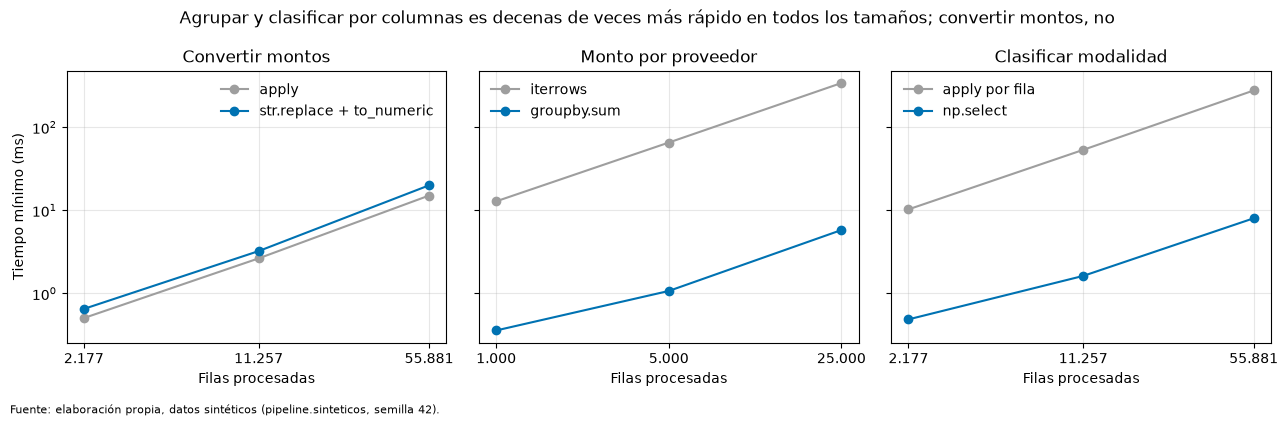

In [4]:
REFERENCE, PIPELINE = "#9E9E9E", "#0072B2"

operations = list(table["operacion"].unique())
fig, axes = plt.subplots(1, len(operations), figsize=(13, 4), sharey=True)
for ax, operation in zip(axes, operations):
    subset = table[table["operacion"] == operation]
    for in_pipeline, color in [(False, REFERENCE), (True, PIPELINE)]:
        version = subset[subset["en_pipeline"] == in_pipeline]
        ax.plot(version["filas"], version["tiempo_ms"], marker="o", color=color, label=version["version"].iloc[0])
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.minorticks_off()
    ax.set_xticks(list(version["filas"]))  # una marca por tamaño medido
    ax.set_xticklabels([f"{rows:,}".replace(",", ".") for rows in version["filas"]])
    ax.set_title(operation)
    ax.set_xlabel("Filas procesadas")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Tiempo mínimo (ms)")
fig.suptitle("Agrupar y clasificar por columnas es decenas de veces más rápido en todos los tamaños; convertir montos, no")
fig.text(0.01, -0.03, "Fuente: elaboración propia, datos sintéticos (pipeline.sinteticos, semilla 42).", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Interpretación

In [5]:
from IPython.display import Markdown

small, large = ratios.columns[0], ratios.columns[-1]


def es(number, decimals=1):
    """Número con coma decimal y punto de miles."""
    return f"{number:,.{decimals}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def trend(operation):
    return f"de {es(ratios.loc[operation, small])} a {es(ratios.loc[operation, large])} veces"


memory = table[table["ordenes"] == large].set_index(["operacion", "en_pipeline"])["memoria_kib"]

Markdown(f"""
- **Monto por proveedor:** `groupby.sum` es más rápido que `iterrows` en todos los tamaños, y la razón pasa {trend("Monto por proveedor")} entre {es(small, 0)} y {es(large, 0)} órdenes. Las dos versiones crecen en proporción a las filas, pero el bucle paga la creación de un objeto por fila.
- **Clasificar modalidad:** `np.select` supera a `apply` por fila, con una razón que pasa {trend("Clasificar modalidad")}. En el tamaño mayor usa {es(memory[("Clasificar modalidad", True)] / 1024)} MiB contra {es(memory[("Clasificar modalidad", False)] / 1024)} MiB.
- **Convertir montos:** la razón queda bajo 1 en todos los tamaños ({trend("Convertir montos")}): la versión vectorizada no es más rápida que `apply`. Las dos recorren el texto celda por celda; vectorizar no ahorra trabajo cuando el costo está en leer cadenas. Se conserva la versión del pipeline porque trata los datos ausentes sin código adicional, no por velocidad.
- **Complejidad:** en las tres operaciones, el tiempo de las dos versiones crece aproximadamente en proporción a las filas (rectas en el gráfico). Lo que distingue a las versiones es el costo por fila, no el orden de crecimiento, y en ningún tamaño medido la ventaja se invierte. La memoria también crece con las filas.
- **Qué decide esto en el proyecto:** con 10.285 órdenes, el pipeline completo tarda fracciones de segundo y cualquier versión serviría. La elección importa si el estudio se amplía a más meses o regiones: con 25.000 órdenes, el bucle con `iterrows` ya tarda cientos de milisegundos por indicador.
- **Límite:** los tiempos dependen del equipo y cambian entre ejecuciones; lo comparable es la razón. Los datos son sintéticos: tienen la forma de la fuente, no su contenido.
""")


- **Monto por proveedor:** `groupby.sum` es más rápido que `iterrows` en todos los tamaños, y la razón pasa de 35,7 a 58,7 veces entre 1.000 y 25.000 órdenes. Las dos versiones crecen en proporción a las filas, pero el bucle paga la creación de un objeto por fila.
- **Clasificar modalidad:** `np.select` supera a `apply` por fila, con una razón que pasa de 21,1 a 34,5 veces. En el tamaño mayor usa 10,0 MiB contra 52,3 MiB.
- **Convertir montos:** la razón queda bajo 1 en todos los tamaños (de 0,8 a 0,8 veces): la versión vectorizada no es más rápida que `apply`. Las dos recorren el texto celda por celda; vectorizar no ahorra trabajo cuando el costo está en leer cadenas. Se conserva la versión del pipeline porque trata los datos ausentes sin código adicional, no por velocidad.
- **Complejidad:** en las tres operaciones, el tiempo de las dos versiones crece aproximadamente en proporción a las filas (rectas en el gráfico). Lo que distingue a las versiones es el costo por fila, no el orden de crecimiento, y en ningún tamaño medido la ventaja se invierte. La memoria también crece con las filas.
- **Qué decide esto en el proyecto:** con 10.285 órdenes, el pipeline completo tarda fracciones de segundo y cualquier versión serviría. La elección importa si el estudio se amplía a más meses o regiones: con 25.000 órdenes, el bucle con `iterrows` ya tarda cientos de milisegundos por indicador.
- **Límite:** los tiempos dependen del equipo y cambian entre ejecuciones; lo comparable es la razón. Los datos son sintéticos: tienen la forma de la fuente, no su contenido.
